# ASD convergence

Test concordance between molecular effects and ASD-associated genes.


In [1]:
import hashlib
import json
from importlib.metadata import version
from pathlib import Path

import gseapy as gp
import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy.stats import fisher_exact, hypergeom, norm, rankdata, spearmanr
from statsmodels.stats.multitest import multipletests

ALPHA = 0.05
MIN_SET_SIZE = 10
MAX_SET_SIZE = 500
MIN_GENE_PROPORTION = 0.1
PERMUTATIONS = 1_000
THREADS = 8
RANDOM_SEED = 1077
PRIMARY_VARIANT = 'stable'
EXPECTED_GSEAPY_VERSION = '1.3.1'
ANALYSES = {
    'input': 'inputDifferentialExpression.tsv',
    'monosome': 'monosomeDifferentialAbundance.tsv',
    'polysome': 'polysomeDifferentialAbundance.tsv',
    'redistribution': 'polysomeMonosome.tsv',
}
LABELS = {
    'input': 'Input',
    'monosome': 'Monosome',
    'polysome': 'Polysome',
    'redistribution': 'Redistribution',
}
VARIANTS = {
    'all': 'All tested transcripts',
    'stable': 'Exclude structural-zero and extreme effects',
    'highConfidence': 'Stable and mean gene proportion ≥ 0.10',
}
FUNCTIONAL_COLLECTIONS = {
    'goBiologicalProcess': 'GO BP',
    'goCellularComponent': 'GO CC',
    'goMolecularFunction': 'GO MF',
    'synGO': 'SynGO',
}

sns.set_theme(style = 'ticks', context = 'notebook')


In [2]:
# Locate the project and load the upstream analysis products.


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / 'data').is_dir() and (path / 'results').is_dir():
            return path
    raise FileNotFoundError('Could not find the project root.')


def strip_version(values: pd.Series) -> pd.Series:
    return values.astype('string').str.replace(r'\..*$', '', regex = True)


ROOT = find_root(Path.cwd().resolve())
DATA_DIR = ROOT / 'data'
GENE_SET_DIR = DATA_DIR / 'geneSets'
REFERENCE_DIR = DATA_DIR / 'reference'
RESULTS_DIR = ROOT / 'results'
FU_PATH = REFERENCE_DIR / 'fu2022SupplementaryTables.xlsx'

transcript_results = pd.read_csv(
    RESULTS_DIR / 'transcriptAbundanceComparison.tsv',
    sep = '\t',
)
transcript_features = pd.read_csv(
    RESULTS_DIR / 'transcriptFeatures.tsv',
    sep = '\t',
)
dtu_genes = pd.read_csv(
    RESULTS_DIR / 'dtuGeneComparison.tsv',
    sep = '\t',
)
gene_results = {
    analysis: pd.read_csv(RESULTS_DIR / filename, sep = '\t')
    for analysis, filename in ANALYSES.items()
}
manifest = pd.read_csv(
    GENE_SET_DIR / 'geneSetManifest.tsv',
    sep = '\t',
)

if gp.__version__ != EXPECTED_GSEAPY_VERSION:
    raise RuntimeError(
        f'Expected GSEApy {EXPECTED_GSEAPY_VERSION}, found '
        f'{gp.__version__}.'
    )
if not FU_PATH.is_file():
    raise FileNotFoundError('Fu et al. supplementary tables are missing.')


In [3]:
# Pin the exact ASD-only Fu et al. tiers.


def read_excel_sheet(path: Path, sheet_name: str) -> pd.DataFrame:
    workbook = openpyxl.load_workbook(
        path,
        read_only = True,
        data_only = True,
    )
    sheet = workbook[sheet_name]
    rows = sheet.iter_rows(values_only = True)
    columns = next(rows)
    table = pd.DataFrame(rows, columns = columns)
    workbook.close()
    return table


fu_raw = read_excel_sheet(FU_PATH, 'Supplementary Table 11')
required_fu = {'gene', 'gene_id', 'ASD72', 'ASD185', 'FDR_TADA_ASD'}
missing_fu = required_fu.difference(fu_raw.columns)
if missing_fu:
    raise ValueError(f'Fu table is missing columns: {sorted(missing_fu)}')

fu_genes = fu_raw.loc[
    fu_raw['ASD185'].eq(True),
    ['gene_id', 'gene', 'FDR_TADA_ASD', 'ASD72', 'ASD185'],
].rename(columns = {
    'gene_id': 'geneId',
    'gene': 'geneName',
    'FDR_TADA_ASD': 'asdAdjustedPValue',
    'ASD72': 'fuAsd72',
    'ASD185': 'fuAsd185',
})
fu_genes['geneId'] = fu_genes['geneId'].astype('string')
fu_genes['geneName'] = fu_genes['geneName'].astype('string')
fu_genes[['fuAsd72', 'fuAsd185']] = fu_genes[
    ['fuAsd72', 'fuAsd185']
].astype(bool)

if len(fu_genes) != 185 or fu_genes['fuAsd72'].sum() != 72:
    raise ValueError('Fu ASD tier sizes do not match the publication.')
if fu_genes['geneId'].isna().any() or not fu_genes['geneId'].is_unique:
    raise ValueError('Fu ASD gene identifiers must be complete and unique.')
if not fu_genes.loc[fu_genes['fuAsd72'], 'fuAsd185'].all():
    raise ValueError('The Fu 72-gene tier must be nested in the 185-gene tier.')

fu72_symbols = set(
    fu_genes.loc[fu_genes['fuAsd72'], 'geneName'].str.upper()
)
fu185_symbols = set(fu_genes['geneName'].str.upper())

display(pd.DataFrame({
    'tier': ['Fu ASD FDR ≤ 0.001', 'Fu ASD FDR ≤ 0.05'],
    'genes': [len(fu72_symbols), len(fu185_symbols)],
}))


,tier,genes
0,Fu ASD FDR ≤ 0.001,72
1,Fu ASD FDR ≤ 0.05,185


In [4]:
# Collapse transcript tests to one valid gene-level minimum-P test.
# Bonferroni within gene is valid under arbitrary transcript dependence.


def combine_transcript_tests(analysis: str, variant: str) -> pd.DataFrame:
    p_column = f'{analysis}PValue'
    lfc_column = f'{analysis}Log2FoldChange'
    proportion_column = f'{analysis}MeanGeneProportion'
    eligible = transcript_results[p_column].notna()

    if variant in {'stable', 'highConfidence'}:
        eligible &= ~transcript_results[
            f'{analysis}StructuralZero'
        ].fillna(False)
        eligible &= ~transcript_results[
            f'{analysis}ExtremeEffect'
        ].fillna(False)
    if variant == 'highConfidence':
        eligible &= transcript_results[proportion_column].ge(
            MIN_GENE_PROPORTION
        )

    columns = [
        'transcriptId',
        'parentGeneId',
        'geneName',
        p_column,
        lfc_column,
        proportion_column,
        f'{analysis}ParentGeneAdjustedPValue',
        f'{analysis}ParentGeneFdr',
    ]
    table = transcript_results.loc[eligible, columns].copy()
    table['geneId'] = strip_version(table['parentGeneId'])
    table = table.sort_values(
        ['geneId', p_column, 'transcriptId'],
        ascending = [True, True, True],
    )
    table['testedTranscriptCount'] = table.groupby(
        'geneId',
        observed = True,
    )['transcriptId'].transform('size')
    lead = table.drop_duplicates('geneId', keep = 'first').copy()
    lead = lead.rename(columns = {
        'transcriptId': 'leadTranscriptId',
        p_column: 'leadTranscriptPValue',
        lfc_column: 'leadTranscriptLog2FoldChange',
        proportion_column: 'leadTranscriptMeanGeneProportion',
        f'{analysis}ParentGeneAdjustedPValue': (
            'parentGeneAdjustedPValue'
        ),
        f'{analysis}ParentGeneFdr': 'parentGeneFdr',
    })
    lead['genePValue'] = (
        lead['leadTranscriptPValue'] * lead['testedTranscriptCount']
    ).clip(upper = 1)
    lead['geneAdjustedPValue'] = multipletests(
        lead['genePValue'],
        method = 'fdr_bh',
    )[1]
    lead['geneFdr'] = lead['geneAdjustedPValue'].lt(ALPHA)
    lead['parentGeneTested'] = lead[
        'parentGeneAdjustedPValue'
    ].notna()
    lead['withoutParentGeneFdr'] = (
        lead['geneFdr']
        & lead['parentGeneTested']
        & ~lead['parentGeneFdr'].fillna(False)
    )
    lead['direction'] = np.select(
        [
            lead['leadTranscriptLog2FoldChange'].gt(0),
            lead['leadTranscriptLog2FoldChange'].lt(0),
        ],
        ['positive', 'negative'],
        default = 'zero',
    )
    lead.insert(0, 'analysis', analysis)
    lead.insert(1, 'variant', variant)

    gene_table = gene_results[analysis].copy()
    gene_table['geneId'] = strip_version(gene_table['geneId'])
    if not gene_table['geneId'].is_unique:
        raise ValueError(f'Non-unique gene IDs in {analysis} results.')
    base_mean = gene_table.set_index('geneId')['baseMean']
    lead['parentGeneBaseMean'] = lead['geneId'].map(base_mean)

    fu_index = fu_genes.set_index('geneId')
    lead['fuAsd72'] = lead['geneId'].isin(
        fu_index.index[fu_index['fuAsd72']]
    )
    lead['fuAsd185'] = lead['geneId'].isin(fu_index.index)

    feature_columns = [
        'transcriptId',
        'architectureEligible',
        'fivePrimeUtrLength',
        'hasCandidateUorf',
        'hasOverlappingUorf',
        'cdsLength',
        'threePrimeUtrLength',
    ]
    feature_map = transcript_features[feature_columns].set_index(
        'transcriptId'
    )
    lead = lead.join(feature_map, on = 'leadTranscriptId')
    return lead


combined_tables = [
    combine_transcript_tests(analysis, variant)
    for analysis in ANALYSES
    for variant in VARIANTS
]
all_gene_evidence = pd.concat(combined_tables, ignore_index = True)
transcript_gene_evidence = all_gene_evidence.loc[
    all_gene_evidence['variant'].eq(PRIMARY_VARIANT)
].copy()

sensitivity_records = []
for (analysis, variant), table in all_gene_evidence.groupby(
    ['analysis', 'variant'],
    sort = False,
    observed = True,
):
    selected = table['geneFdr']
    without_parent = table['withoutParentGeneFdr']
    sensitivity_records.append({
        'analysis': analysis,
        'variant': variant,
        'variantDescription': VARIANTS[variant],
        'testedGenes': len(table),
        'geneFdrGenes': int(selected.sum()),
        'withoutParentGeneFdrGenes': int(without_parent.sum()),
        'positiveGenes': int(
            (without_parent & table['direction'].eq('positive')).sum()
        ),
        'negativeGenes': int(
            (without_parent & table['direction'].eq('negative')).sum()
        ),
        'fuAsd72Genes': int((without_parent & table['fuAsd72']).sum()),
        'fuAsd185Genes': int(
            (without_parent & table['fuAsd185']).sum()
        ),
    })

transcript_gene_sensitivity = pd.DataFrame(sensitivity_records)
display(transcript_gene_sensitivity)


,analysis,variant,variantDescription,testedGenes,geneFdrGenes,withoutParentGeneFdrGenes,positiveGenes,negativeGenes,fuAsd72Genes,fuAsd185Genes
0,input,all,All tested transcripts,14372,515,398,183,215,5,9
1,input,stable,Exclude structural-zero and extreme effects,14342,298,211,95,116,4,7
2,input,highConfidence,Stable and mean gene proportion ≥ 0.10,14330,246,161,79,82,3,5
3,monosome,all,All tested transcripts,12980,378,301,190,111,4,4
4,monosome,stable,Exclude structural-zero and extreme effects,12950,145,92,54,38,0,0
5,monosome,highConfidence,Stable and mean gene proportion ≥ 0.10,12930,110,60,33,27,0,0
6,polysome,all,All tested transcripts,13842,412,339,179,160,1,2
7,polysome,stable,Exclude structural-zero and extreme effects,13812,179,135,63,72,0,0
8,polysome,highConfidence,Stable and mean gene proportion ≥ 0.10,13799,122,80,40,40,0,0
9,redistribution,all,All tested transcripts,12234,127,121,74,47,0,1


In [5]:
# Diagnose whether gene selection remains associated with isoform count.

bias_records = []

for analysis, table in transcript_gene_evidence.groupby(
    'analysis',
    sort = False,
    observed = True,
):
    model_table = table.loc[
        table['parentGeneBaseMean'].notna()
    ].copy()
    model_table['logTranscriptCount'] = np.log1p(
        model_table['testedTranscriptCount']
    )
    model_table['logBaseMean'] = np.log1p(
        model_table['parentGeneBaseMean']
    )
    predictors = ['logTranscriptCount', 'logBaseMean']
    design = model_table[predictors].copy()
    design = (design - design.mean()) / design.std(ddof = 0)
    design = sm.add_constant(design, has_constant = 'add')
    fit = sm.GLM(
        model_table['geneFdr'].astype(int),
        design,
        family = sm.families.Binomial(),
    ).fit()

    for predictor in predictors:
        bias_records.append({
            'analysis': analysis,
            'predictor': predictor,
            'genes': len(model_table),
            'coefficient': fit.params[predictor],
            'oddsRatioPerSd': np.exp(fit.params[predictor]),
            'confidenceIntervalLow': np.exp(
                fit.conf_int().loc[predictor, 0]
            ),
            'confidenceIntervalHigh': np.exp(
                fit.conf_int().loc[predictor, 1]
            ),
            'pValue': fit.pvalues[predictor],
        })

transcript_selection_bias = pd.DataFrame(bias_records)
transcript_selection_bias['adjustedPValue'] = multipletests(
    transcript_selection_bias['pValue'],
    method = 'fdr_bh',
)[1]


display(transcript_selection_bias)


,analysis,predictor,genes,coefficient,oddsRatioPerSd,confidenceIntervalLow,confidenceIntervalHigh,pValue,adjustedPValue
0,input,logTranscriptCount,14342,0.168711,1.183778,1.026216,1.365531,0.020609,0.032975
1,input,logBaseMean,14342,0.331963,1.393701,1.174486,1.653831,0.000144,0.000574
2,monosome,logTranscriptCount,12950,0.245407,1.278141,1.048160,1.558584,0.015321,0.030643
3,monosome,logBaseMean,12950,0.303835,1.355045,1.066576,1.721534,0.012858,0.030643
4,polysome,logTranscriptCount,13812,0.376288,1.456867,1.203115,1.764139,0.000116,0.000574
5,polysome,logBaseMean,13812,-0.074747,0.927979,0.748361,1.150706,0.495865,0.495865
6,redistribution,logTranscriptCount,11971,0.266014,1.304754,0.964744,1.764593,0.084176,0.112234
7,redistribution,logBaseMean,11971,0.141115,1.151557,0.795800,1.666355,0.454170,0.495865


In [6]:
# Test direction-specific functional overrepresentation in gene-centric sets.

functional_gene_sets = {}
for collection in FUNCTIONAL_COLLECTIONS:
    row = manifest.loc[manifest['collection'].eq(collection)].squeeze()
    if row.empty:
        raise ValueError(f'Missing gene-set manifest row: {collection}')
    terms = gp.read_gmt(str(GENE_SET_DIR / row.fileName))
    functional_gene_sets[collection] = {
        str(term): {str(gene).upper() for gene in genes}
        for term, genes in terms.items()
    }


def run_functional_ora(
    analysis: str,
    table: pd.DataFrame,
    collection: str,
    terms: dict[str, set[str]],
    direction: str,
) -> pd.DataFrame:
    mapped = table.copy()
    mapped['geneSymbol'] = (
        mapped['geneName'].astype('string').str.strip().str.upper()
    )
    mapped = mapped.loc[
        mapped['geneSymbol'].notna()
        & mapped['geneSymbol'].ne('')
        & ~mapped['geneSymbol'].str.startswith('ENSG')
    ]
    universe = set(mapped['geneSymbol'])
    selected = set(mapped.loc[
        mapped['withoutParentGeneFdr']
        & mapped['direction'].eq(direction),
        'geneSymbol',
    ])
    M = len(universe)
    N = len(selected)
    records = []

    for term, genes in terms.items():
        members = universe.intersection(genes)
        n = len(members)
        if not MIN_SET_SIZE <= n <= MAX_SET_SIZE:
            continue
        overlap = sorted(selected.intersection(members))
        k = len(overlap)
        expected = N * n / M
        contingency = [[k, N - k], [n - k, M - N - n + k]]
        odds_ratio = fisher_exact(
            contingency,
            alternative = 'greater',
        ).statistic
        records.append({
            'analysis': analysis,
            'collection': collection,
            'term': term,
            'direction': direction,
            'universeGenes': M,
            'selectedGenes': N,
            'geneSetSize': n,
            'overlapGenesCount': k,
            'expectedOverlap': expected,
            'enrichmentRatio': k / expected if expected else np.nan,
            'oddsRatio': odds_ratio,
            'pValue': hypergeom.sf(k - 1, M, n, N),
            'overlapGenes': ';'.join(overlap),
        })

    frame = pd.DataFrame(records)
    frame['adjustedPValue'] = multipletests(
        frame['pValue'],
        method = 'fdr_bh',
    )[1]
    return frame


functional_tables = []
for analysis, table in transcript_gene_evidence.groupby(
    'analysis',
    sort = False,
    observed = True,
):
    for collection, terms in functional_gene_sets.items():
        for direction in ('positive', 'negative'):
            functional_tables.append(
                run_functional_ora(
                    analysis,
                    table,
                    collection,
                    terms,
                    direction,
                )
            )

transcript_functional_ora = pd.concat(
    functional_tables,
    ignore_index = True,
).sort_values(
    [
        'analysis',
        'collection',
        'direction',
        'adjustedPValue',
        'pValue',
    ]
)
functional_summary = transcript_functional_ora.groupby(
    ['analysis', 'collection', 'direction'],
    observed = True,
).agg(
    selectedGenes = ('selectedGenes', 'first'),
    testedTerms = ('term', 'size'),
    fdrTerms = ('adjustedPValue', lambda values: values.lt(ALPHA).sum()),
).reset_index()
display(functional_summary)


,analysis,collection,direction,selectedGenes,testedTerms,fdrTerms
0,input,goBiologicalProcess,negative,113,2840,0
1,input,goBiologicalProcess,positive,92,2840,0
2,input,goCellularComponent,negative,113,288,0
3,input,goCellularComponent,positive,92,288,0
4,input,goMolecularFunction,negative,113,541,0
5,input,goMolecularFunction,positive,92,541,0
6,input,synGO,negative,113,70,0
7,input,synGO,positive,92,70,0
8,monosome,goBiologicalProcess,negative,35,2586,0
9,monosome,goBiologicalProcess,positive,51,2586,0


In [7]:
# Show nontrivial FDR terms without treating redundant GO terms as independent.

leading_functional = transcript_functional_ora.loc[
    transcript_functional_ora['adjustedPValue'].lt(ALPHA)
    & transcript_functional_ora['overlapGenesCount'].ge(3)
].copy()
leading_functional = leading_functional.sort_values(
    [
        'adjustedPValue',
        'pValue',
        'analysis',
        'collection',
    ]
)


def covariate_sensitivity(row: pd.Series) -> dict:
    table = transcript_gene_evidence.loc[
        transcript_gene_evidence['analysis'].eq(row['analysis'])
    ].copy()
    table['geneSymbol'] = (
        table['geneName'].astype('string').str.strip().str.upper()
    )
    table = table.loc[
        table['geneSymbol'].notna()
        & table['geneSymbol'].ne('')
        & ~table['geneSymbol'].str.startswith('ENSG')
        & table['parentGeneBaseMean'].notna()
    ]
    selected_symbols = set(table.loc[
        table['withoutParentGeneFdr']
        & table['direction'].eq(row['direction']),
        'geneSymbol',
    ])
    table = table.sort_values(
        ['parentGeneBaseMean', 'geneId'],
        ascending = [False, True],
    ).drop_duplicates('geneSymbol', keep = 'first')
    members = functional_gene_sets[row['collection']][row['term']]
    table['member'] = table['geneSymbol'].isin(members).astype(int)
    table['selected'] = table['geneSymbol'].isin(
        selected_symbols
    ).astype(int)
    covariates = pd.DataFrame({
        'logTranscriptCount': np.log1p(table['testedTranscriptCount']),
        'logBaseMean': np.log1p(table['parentGeneBaseMean']),
    })
    covariates = (
        covariates - covariates.mean()
    ) / covariates.std(ddof = 0)
    design = pd.concat(
        [table[['member']].reset_index(drop = True), covariates.reset_index(
            drop = True
        )],
        axis = 1,
    )
    design = sm.add_constant(design, has_constant = 'add')
    fit = sm.GLM(
        table['selected'].reset_index(drop = True),
        design,
        family = sm.families.Binomial(),
    ).fit(cov_type = 'HC3')
    confidence = fit.conf_int().loc['member']
    return {
        'analysis': row['analysis'],
        'collection': row['collection'],
        'direction': row['direction'],
        'term': row['term'],
        'genes': len(table),
        'coefficient': fit.params['member'],
        'oddsRatio': np.exp(fit.params['member']),
        'confidenceIntervalLow': np.exp(confidence.iloc[0]),
        'confidenceIntervalHigh': np.exp(confidence.iloc[1]),
        'pValue': fit.pvalues['member'],
    }


transcript_functional_covariate_sensitivity = pd.DataFrame([
    covariate_sensitivity(row)
    for _, row in leading_functional.iterrows()
])
if not transcript_functional_covariate_sensitivity.empty:
    transcript_functional_covariate_sensitivity[
        'selectedTermAdjustedPValue'
    ] = multipletests(
        transcript_functional_covariate_sensitivity['pValue'],
        method = 'fdr_bh',
    )[1]

display(leading_functional.head(30))
display(transcript_functional_covariate_sensitivity)


,analysis,collection,term,direction,universeGenes,selectedGenes,geneSetSize,overlapGenesCount,expectedOverlap,enrichmentRatio,oddsRatio,pValue,overlapGenes,adjustedPValue
12729,monosome,goCellularComponent,Cytosolic Small Ribosomal Subunit (GO:0022627),positive,11612,51,36,4,0.158112,25.298475,30.662234,0.000018,RPS12;RPS20;RPS8;RPS9,0.003000
12880,monosome,goCellularComponent,Small Ribosomal Subunit (GO:0015935),positive,11612,51,38,4,0.166896,23.966976,28.853567,0.000022,RPS12;RPS20;RPS8;RPS9,0.003000
14326,polysome,goBiologicalProcess,Aerobic Electron Transport Chain (GO:0019646),positive,12477,60,63,5,0.302957,16.503968,19.371473,0.000012,COX4I1;NDUFA9;NDUFB10;NDUFV2;UQCRH,0.017079
15083,polysome,goBiologicalProcess,Mitochondrial ATP Synthesis Coupled Electron T...,positive,12477,60,63,5,0.302957,16.503968,19.371473,0.000012,COX4I1;NDUFA9;NDUFB10;NDUFV2;UQCRH,0.017079
14480,polysome,goBiologicalProcess,Cellular Respiration (GO:0045333),positive,12477,60,81,5,0.389517,12.836420,14.761962,0.000042,COX4I1;NDUFA9;NDUFB10;NDUFV2;UQCRH,0.038850
19868,polysome,goCellularComponent,COPII-coated ER to Golgi Transport Vesicle (GO...,positive,12477,60,56,4,0.269296,14.853571,16.984890,0.000147,GOSR2;HLA-A;IER3IP1;SURF4,0.041814


,analysis,collection,direction,term,genes,coefficient,oddsRatio,confidenceIntervalLow,confidenceIntervalHigh,pValue,selectedTermAdjustedPValue
0,monosome,goCellularComponent,positive,Cytosolic Small Ribosomal Subunit (GO:0022627),11612,1.239647,3.454392,1.014631,11.760756,4.734499e-02,5.681398e-02
1,monosome,goCellularComponent,positive,Small Ribosomal Subunit (GO:0015935),11612,1.139944,3.126594,0.910590,10.735445,7.011721e-02,7.011721e-02
2,polysome,goBiologicalProcess,positive,Aerobic Electron Transport Chain (GO:0019646),12477,2.521622,12.448770,4.871355,31.812884,1.382475e-07,4.652606e-07
3,polysome,goBiologicalProcess,positive,Mitochondrial ATP Synthesis Coupled Electron T...,12477,2.515034,12.367026,4.832982,31.645751,1.550869e-07,4.652606e-07
4,polysome,goBiologicalProcess,positive,Cellular Respiration (GO:0045333),12477,2.277620,9.753435,3.869525,24.584280,1.374433e-06,2.061650e-06
5,polysome,goCellularComponent,positive,COPII-coated ER to Golgi Transport Vesicle (GO...,12477,2.695016,14.805762,5.065805,43.272609,8.433795e-07,1.686759e-06


In [8]:
# Run gene-set permutation GSEA for the nested Fu ASD-only tiers.

fu_sets = {
    'Fu ASD FDR ≤ 0.001': fu_genes.loc[
        fu_genes['fuAsd72'], 'geneId'
    ].tolist(),
    'Fu ASD FDR ≤ 0.05': fu_genes['geneId'].tolist(),
}
fu_symbol_map = fu_genes.set_index('geneId')['geneName'].to_dict()


def run_fu_prerank(
    ranking: pd.DataFrame,
    context: str,
) -> pd.DataFrame:
    ranking = ranking.dropna().copy()
    ranking = ranking.sort_values(
        ['statistic', 'geneId'],
        ascending = [False, True],
    )
    if ranking['geneId'].duplicated().any():
        raise ValueError(f'Duplicate ranked gene IDs for {context}.')

    result = gp.prerank(
        rnk = ranking[['geneId', 'statistic']],
        gene_sets = fu_sets,
        min_size = MIN_SET_SIZE,
        max_size = MAX_SET_SIZE,
        permutation_num = PERMUTATIONS,
        weight = 1,
        ascending = False,
        threads = THREADS,
        outdir = None,
        no_plot = True,
        seed = RANDOM_SEED,
        verbose = False,
    ).res2d.rename(columns = {
        'Term': 'tier',
        'ES': 'enrichmentScore',
        'NES': 'normalizedEnrichmentScore',
        'NOM p-val': 'pValue',
        'FDR q-val': 'gseaAdjustedPValue',
        'FWER p-val': 'familyWisePValue',
        'Lead_genes': 'leadingEdgeGeneIds',
    })
    result.insert(0, 'context', context)
    tags = result['Tag %'].str.split('/', expand = True).astype(int)
    result['direction'] = np.where(
        result['normalizedEnrichmentScore'].gt(0),
        'positive',
        'negative',
    )
    result['leadingEdgeGenes'] = result[
        'leadingEdgeGeneIds'
    ].map(
        lambda value: ';'.join(
            fu_symbol_map.get(gene_id, gene_id)
            for gene_id in str(value).split(';')
        )
    )
    result['leadingEdgeGenesCount'] = result[
        'leadingEdgeGeneIds'
    ].str.count(';').add(1)
    result['geneSetSize'] = tags[1]
    result['leadingEdgeFraction'] = (
        result['leadingEdgeGenesCount'] / result['geneSetSize']
    )
    result['rankAtPeakFraction'] = (
        result['Gene %'].str.removesuffix('%').astype(float) / 100
    )
    minimum_p = 1 / (PERMUTATIONS + 1)
    for column in ('pValue', 'gseaAdjustedPValue', 'familyWisePValue'):
        result[column] = result[column].astype(float).clip(
            lower = minimum_p
        )
    result['permutations'] = PERMUTATIONS
    result['threads'] = THREADS
    return result[[
        'context',
        'tier',
        'direction',
        'enrichmentScore',
        'normalizedEnrichmentScore',
        'pValue',
        'gseaAdjustedPValue',
        'familyWisePValue',
        'geneSetSize',
        'leadingEdgeGenesCount',
        'leadingEdgeFraction',
        'rankAtPeakFraction',
        'leadingEdgeGeneIds',
        'leadingEdgeGenes',
        'permutations',
        'threads',
    ]]


fu_ranked_tables = []
for analysis, table in gene_results.items():
    ranking = table[['geneId', 'statistic']].copy()
    ranking['geneId'] = strip_version(ranking['geneId'])
    fu_ranked_tables.append(run_fu_prerank(ranking, analysis))

fu_ranked_enrichment = pd.concat(
    fu_ranked_tables,
    ignore_index = True,
)
fu_ranked_enrichment['globalAdjustedPValue'] = multipletests(
    fu_ranked_enrichment['pValue'],
    method = 'fdr_bh',
)[1]
fu_ranked_enrichment['tierAdjustedPValue'] = fu_ranked_enrichment.groupby(
    'tier',
    observed = True,
)['pValue'].transform(
    lambda values: multipletests(values, method = 'fdr_bh')[1]
)
fu_ranked_enrichment['primaryTier'] = fu_ranked_enrichment['tier'].eq(
    'Fu ASD FDR ≤ 0.001'
)
fu_ranked_enrichment = fu_ranked_enrichment.sort_values(
    ['globalAdjustedPValue', 'pValue', 'context', 'tier']
)

transcript_count_map = transcript_results.assign(
    geneId = strip_version(transcript_results['parentGeneId'])
).groupby('geneId', observed = True)['parentTranscriptCount'].max()
rank_regression_records = []

for analysis, table in gene_results.items():
    model_table = table[['geneId', 'baseMean', 'statistic']].copy()
    model_table['geneId'] = strip_version(model_table['geneId'])
    model_table = model_table.dropna(
        subset = ['baseMean', 'statistic']
    ).reset_index(drop = True)
    model_table['rankNormalStatistic'] = norm.ppf(
        (rankdata(model_table['statistic']) - 0.5) / len(model_table)
    )
    model_table['annotatedTranscriptCount'] = (
        model_table['geneId'].map(transcript_count_map).fillna(0)
    )

    for tier, genes in fu_sets.items():
        model_table['fuMember'] = model_table['geneId'].isin(genes).astype(int)
        covariates = pd.DataFrame({
            'logBaseMean': np.log1p(model_table['baseMean']),
            'logTranscriptCount': np.log1p(
                model_table['annotatedTranscriptCount']
            ),
        })
        covariates = (
            covariates - covariates.mean()
        ) / covariates.std(ddof = 0)
        design = pd.concat(
            [model_table[['fuMember']], covariates],
            axis = 1,
        )
        design = sm.add_constant(design, has_constant = 'add')
        fit = sm.OLS(
            model_table['rankNormalStatistic'],
            design,
        ).fit(cov_type = 'HC3')
        confidence = fit.conf_int().loc['fuMember']
        rank_regression_records.append({
            'analysis': analysis,
            'tier': tier,
            'genes': len(model_table),
            'asdGenes': int(model_table['fuMember'].sum()),
            'coefficient': fit.params['fuMember'],
            'confidenceIntervalLow': confidence.iloc[0],
            'confidenceIntervalHigh': confidence.iloc[1],
            'pValue': fit.pvalues['fuMember'],
        })

fu_rank_regression = pd.DataFrame(rank_regression_records)
fu_rank_regression['adjustedPValue'] = multipletests(
    fu_rank_regression['pValue'],
    method = 'fdr_bh',
)[1]
fu_rank_regression['direction'] = np.where(
    fu_rank_regression['coefficient'].gt(0),
    'positive',
    'negative',
)
display(fu_ranked_enrichment)
display(fu_rank_regression)


,context,tier,direction,enrichmentScore,normalizedEnrichmentScore,pValue,gseaAdjustedPValue,familyWisePValue,geneSetSize,leadingEdgeGenesCount,leadingEdgeFraction,rankAtPeakFraction,leadingEdgeGeneIds,leadingEdgeGenes,permutations,threads,globalAdjustedPValue,tierAdjustedPValue,primaryTier
3,monosome,Fu ASD FDR ≤ 0.05,positive,0.335587,1.600765,0.000999,0.005487,0.004000,182,55,0.302198,0.1674,ENSG00000131242;ENSG00000116539;ENSG0000006779...,RAB11FIP4;ASH1L;NAV3;KMT2C;TSC1;ATG9B;PAX5;ZBT...,1000,8,0.002664,0.001998,False
6,redistribution,Fu ASD FDR ≤ 0.001,negative,-0.526102,-2.313158,0.000999,0.000999,0.000999,72,28,0.388889,0.1878,ENSG00000197102;ENSG00000100888;ENSG0000018172...,DYNC1H1;CHD8;ZBTB20;KMT2A;NAA15;ASH1L;ANK2;TCF...,1000,8,0.002664,0.003996,True
7,redistribution,Fu ASD FDR ≤ 0.05,negative,-0.389804,-1.964151,0.000999,0.000999,0.000999,180,61,0.338889,0.1878,ENSG00000173064;ENSG00000170004;ENSG0000019710...,HECTD4;CHD3;DYNC1H1;CHD8;UBR5;ZBTB20;EFTUD2;KM...,1000,8,0.002664,0.001998,False
2,monosome,Fu ASD FDR ≤ 0.001,positive,0.433763,1.768953,0.007712,0.008230,0.003000,72,33,0.458333,0.2730,ENSG00000116539;ENSG00000055609;ENSG0000018172...,ASH1L;KMT2C;ZBTB20;PLXNA1;ANKRD11;KCNMA1;DSCAM...,1000,8,0.015424,0.015424,True
4,polysome,Fu ASD FDR ≤ 0.001,negative,-0.288680,-1.123450,0.243243,0.455285,0.298942,72,24,0.333333,0.2717,ENSG00000181722;ENSG00000164134;ENSG0000010088...,ZBTB20;NAA15;CHD8;DYNC1H1;GIGYF1;CTNNB1;MED23;...,1000,8,0.389189,0.324324,True
5,polysome,Fu ASD FDR ≤ 0.05,negative,-0.236398,-1.067587,0.319749,0.326016,0.400794,180,65,0.361111,0.2949,ENSG00000108883;ENSG00000181722;ENSG0000016413...,EFTUD2;ZBTB20;NAA15;CHD8;DYNC1H1;ZMYND8;UBR5;G...,1000,8,0.426332,0.426332,False
0,input,Fu ASD FDR ≤ 0.001,positive,0.210727,0.825602,0.817330,0.862500,0.489000,72,26,0.361111,0.3148,ENSG00000114554;ENSG00000156113;ENSG0000017158...,PLXNA1;KCNMA1;DSCAM;DEAF1;SHANK3;SPAST;FOXP1;K...,1000,8,0.934092,0.817330,True
1,input,Fu ASD FDR ≤ 0.05,negative,-0.172103,-0.730520,0.985646,0.960833,0.974801,182,35,0.192308,0.1977,ENSG00000103546;ENSG00000119772;ENSG0000014918...,SLC6A2;DNMT3A;CELF1;CYFIP2;ITPR3;CSNK2A1;KPNA1...,1000,8,0.985646,0.985646,False


,analysis,tier,genes,asdGenes,coefficient,confidenceIntervalLow,confidenceIntervalHigh,pValue,adjustedPValue,direction
0,input,Fu ASD FDR ≤ 0.001,21556,72,0.110351,-0.075387,0.296089,2.442388e-01,2.791300e-01,positive
1,input,Fu ASD FDR ≤ 0.05,21556,182,-0.010887,-0.137783,0.116009,8.664613e-01,8.664613e-01,negative
2,monosome,Fu ASD FDR ≤ 0.001,21888,72,0.505205,0.311567,0.698842,3.161032e-07,7.237806e-07,positive
3,monosome,Fu ASD FDR ≤ 0.05,21888,182,0.369757,0.227322,0.512193,3.618903e-07,7.237806e-07,positive
4,polysome,Fu ASD FDR ≤ 0.001,21256,72,-0.160145,-0.369959,0.049669,1.346578e-01,1.795437e-01,negative
5,polysome,Fu ASD FDR ≤ 0.05,21256,180,-0.113569,-0.250436,0.023299,1.038813e-01,1.662101e-01,negative
6,redistribution,Fu ASD FDR ≤ 0.001,20470,72,-0.709060,-0.926788,-0.491331,1.738033e-10,6.952131e-10,negative
7,redistribution,Fu ASD FDR ≤ 0.05,20470,180,-0.517118,-0.674174,-0.360063,1.094089e-10,6.952131e-10,negative


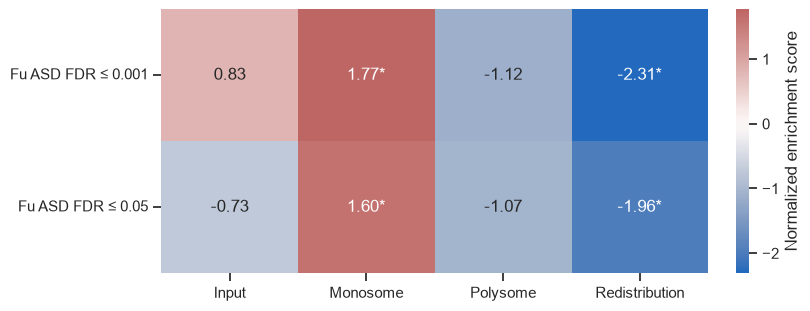

,analysis,tier,direction,universeGenes,selectedGenes,asdGenesInUniverse,overlapGenesCount,expectedOverlap,oddsRatio,pValue,overlapGeneIds,overlapGenes,globalAdjustedPValue
3,input,Fu ASD FDR ≤ 0.05,both,14342,211,161,7,2.368638,3.114305,0.009800,ENSG00000100207;ENSG00000110066;ENSG0000011455...,TCF20;SUV420H1;PLXNA1;DEDD;TAOK1;NACC1;PRH1,0.086403
5,input,Fu ASD FDR ≤ 0.05,negative,14342,116,161,5,1.302189,4.062717,0.009900,ENSG00000100207;ENSG00000110066;ENSG0000015879...,TCF20;SUV420H1;DEDD;TAOK1;NACC1,0.086403
0,input,Fu ASD FDR ≤ 0.001,both,14342,211,63,4,0.926858,4.608859,0.013796,ENSG00000100207;ENSG00000110066;ENSG0000011455...,TCF20;SUV420H1;PLXNA1;TAOK1,0.086403
2,input,Fu ASD FDR ≤ 0.001,negative,14342,116,63,3,0.509552,6.268142,0.014400,ENSG00000100207;ENSG00000110066;ENSG00000160551,TCF20;SUV420H1;TAOK1,0.086403
4,input,Fu ASD FDR ≤ 0.05,positive,14342,95,161,2,1.066448,1.905457,0.288870,ENSG00000114554;ENSG00000231887,PLXNA1;PRH1,1.000000
1,input,Fu ASD FDR ≤ 0.001,positive,14342,95,63,1,0.417306,2.433940,0.342693,ENSG00000114554,PLXNA1,1.000000
6,monosome,Fu ASD FDR ≤ 0.001,both,12950,92,58,0,0.412046,0.000000,1.000000,,,1.000000
7,monosome,Fu ASD FDR ≤ 0.001,positive,12950,54,58,0,0.241853,0.000000,1.000000,,,1.000000
8,monosome,Fu ASD FDR ≤ 0.001,negative,12950,38,58,0,0.170193,0.000000,1.000000,,,1.000000
9,monosome,Fu ASD FDR ≤ 0.05,both,12950,92,146,0,1.037220,0.000000,1.000000,,,1.000000


In [9]:
# Contrast ranked Fu convergence with thresholded transcript-gene overlap.


def run_fu_overlap(
    analysis: str,
    table: pd.DataFrame,
    tier: str,
    members: set[str],
    direction: str,
) -> dict:
    universe = set(table['geneId'])
    selected_mask = table['withoutParentGeneFdr']
    if direction != 'both':
        selected_mask &= table['direction'].eq(direction)
    selected = set(table.loc[selected_mask, 'geneId'])
    tier_members = universe.intersection(members)
    overlap = sorted(selected.intersection(tier_members))
    M = len(universe)
    N = len(selected)
    n = len(tier_members)
    k = len(overlap)
    contingency = [[k, N - k], [n - k, M - N - n + k]]
    odds_ratio = fisher_exact(
        contingency,
        alternative = 'greater',
    ).statistic
    return {
        'analysis': analysis,
        'tier': tier,
        'direction': direction,
        'universeGenes': M,
        'selectedGenes': N,
        'asdGenesInUniverse': n,
        'overlapGenesCount': k,
        'expectedOverlap': N * n / M,
        'oddsRatio': odds_ratio,
        'pValue': hypergeom.sf(k - 1, M, n, N),
        'overlapGeneIds': ';'.join(overlap),
        'overlapGenes': ';'.join(
            fu_symbol_map.get(gene_id, gene_id) for gene_id in overlap
        ),
    }


fu_overlap_records = []
for analysis, table in transcript_gene_evidence.groupby(
    'analysis',
    sort = False,
    observed = True,
):
    for tier, genes in fu_sets.items():
        members = set(genes)
        for direction in ('both', 'positive', 'negative'):
            fu_overlap_records.append(
                run_fu_overlap(
                    analysis,
                    table,
                    tier,
                    members,
                    direction,
                )
            )

fu_transcript_overlap = pd.DataFrame(fu_overlap_records)
fu_transcript_overlap['globalAdjustedPValue'] = multipletests(
    fu_transcript_overlap['pValue'],
    method = 'fdr_bh',
)[1]

nes = fu_ranked_enrichment.pivot(
    index = 'tier',
    columns = 'context',
    values = 'normalizedEnrichmentScore',
).reindex(index = fu_sets, columns = ANALYSES)
global_q = fu_ranked_enrichment.pivot(
    index = 'tier',
    columns = 'context',
    values = 'globalAdjustedPValue',
).reindex(index = fu_sets, columns = ANALYSES)
annotations = nes.map(lambda value: f'{value:.2f}')
annotations = annotations.mask(
    global_q.lt(ALPHA),
    annotations + '*',
)

figure, ax = plt.subplots(figsize = (8, 3), constrained_layout = True)
sns.heatmap(
    nes.rename(columns = LABELS),
    annot = annotations,
    fmt = '',
    center = 0,
    cmap = 'vlag',
    cbar_kws = {'label': 'Normalized enrichment score'},
    ax = ax,
)
ax.set(xlabel = '', ylabel = '')
plt.show()

display(
    fu_transcript_overlap.sort_values(
        ['globalAdjustedPValue', 'pValue']
    ).head(20)
)


In [10]:
# Challenge redistribution enrichment by donor omission and normalization.

leave_one_out = pd.read_csv(
    RESULTS_DIR / 'redistributionLeaveOneOut.tsv',
    sep = '\t',
    dtype = {
        'geneId': 'string',
        'geneName': 'string',
        'omittedParticipantId': 'string',
        'omittedCondition': 'string',
    },
)
loo_tables = []

for participant, table in leave_one_out.groupby(
    'omittedParticipantId',
    sort = True,
    observed = True,
):
    ranking = table[['geneId', 'statistic']].copy()
    ranking['geneId'] = strip_version(ranking['geneId'])
    frame = run_fu_prerank(ranking, f'omit_{participant}')
    frame.insert(1, 'omittedParticipantId', participant)
    frame.insert(2, 'omittedCondition', table['omittedCondition'].iloc[0])
    loo_tables.append(frame)

fu_leave_one_out = pd.concat(loo_tables, ignore_index = True)
fu_leave_one_out['tierAdjustedPValue'] = fu_leave_one_out.groupby(
    'tier',
    observed = True,
)['pValue'].transform(
    lambda values: multipletests(values, method = 'fdr_bh')[1]
)
loo_summary = fu_leave_one_out.groupby('tier', observed = True).agg(
    omittedFits = ('context', 'size'),
    negativeFits = (
        'normalizedEnrichmentScore',
        lambda values: values.lt(0).sum(),
    ),
    minimumNes = ('normalizedEnrichmentScore', 'min'),
    medianNes = ('normalizedEnrichmentScore', 'median'),
    maximumNes = ('normalizedEnrichmentScore', 'max'),
    maximumPValue = ('pValue', 'max'),
).reset_index()

normalization = pd.read_csv(
    RESULTS_DIR / 'normalizationSensitivity.tsv',
    sep = '\t',
)
normalization_tables = []
for context, statistic in {
    'fractionWise': 'fractionWiseStatistic',
    'joint': 'jointStatistic',
}.items():
    ranking = normalization[['geneId', statistic]].rename(
        columns = {statistic: 'statistic'}
    )
    ranking['geneId'] = strip_version(ranking['geneId'])
    normalization_tables.append(run_fu_prerank(ranking, context))

fu_normalization_sensitivity = pd.concat(
    normalization_tables,
    ignore_index = True,
)
display(loo_summary)
display(fu_normalization_sensitivity)


,tier,omittedFits,negativeFits,minimumNes,medianNes,maximumNes,maximumPValue
0,Fu ASD FDR ≤ 0.001,6,6,-2.565159,-2.168092,-1.165768,0.192118
1,Fu ASD FDR ≤ 0.05,6,5,-2.565954,-1.968157,0.915576,0.684976


,context,tier,direction,enrichmentScore,normalizedEnrichmentScore,pValue,gseaAdjustedPValue,familyWisePValue,geneSetSize,leadingEdgeGenesCount,leadingEdgeFraction,rankAtPeakFraction,leadingEdgeGeneIds,leadingEdgeGenes,permutations,threads
0,fractionWise,Fu ASD FDR ≤ 0.001,negative,-0.526102,-2.313158,0.000999,0.000999,0.000999,72,28,0.388889,0.1878,ENSG00000197102;ENSG00000100888;ENSG0000018172...,DYNC1H1;CHD8;ZBTB20;KMT2A;NAA15;ASH1L;ANK2;TCF...,1000,8
1,fractionWise,Fu ASD FDR ≤ 0.05,negative,-0.389804,-1.964151,0.000999,0.000999,0.000999,180,61,0.338889,0.1878,ENSG00000173064;ENSG00000170004;ENSG0000019710...,HECTD4;CHD3;DYNC1H1;CHD8;UBR5;ZBTB20;EFTUD2;KM...,1000,8
2,joint,Fu ASD FDR ≤ 0.001,negative,-0.536768,-2.280470,0.000999,0.000999,0.000999,72,27,0.375000,0.1674,ENSG00000197102;ENSG00000100888;ENSG0000011805...,DYNC1H1;CHD8;KMT2A;ZBTB20;ASH1L;ANK2;NAA15;TCF...,1000,8
3,joint,Fu ASD FDR ≤ 0.05,negative,-0.419694,-2.066465,0.000999,0.000999,0.000999,180,60,0.333333,0.1715,ENSG00000173064;ENSG00000170004;ENSG0000019710...,HECTD4;CHD3;DYNC1H1;CHD8;UBR5;KMT2A;ZBTB20;EFT...,1000,8


In [11]:
# Characterize Fu risk genes driving convergent molecular signals.


def leading_edge_ids(analysis: str, tier: str) -> set[str]:
    rows = fu_ranked_enrichment.loc[
        fu_ranked_enrichment['context'].eq(analysis)
        & fu_ranked_enrichment['tier'].eq(tier)
    ]
    if len(rows) != 1:
        raise ValueError('Expected one Fu enrichment row.')
    return set(rows.iloc[0]['leadingEdgeGeneIds'].split(';'))


primary_tier = 'Fu ASD FDR ≤ 0.001'
monosome_leading = leading_edge_ids('monosome', primary_tier)
redistribution_leading = leading_edge_ids('redistribution', primary_tier)
shared_leading = monosome_leading.intersection(redistribution_leading)
union_leading = monosome_leading.union(redistribution_leading)

fu_leading_edge_genes = fu_genes.loc[
    fu_genes['geneId'].isin(union_leading)
].copy()
fu_leading_edge_genes['monosomeLeadingEdge'] = fu_leading_edge_genes[
    'geneId'
].isin(monosome_leading)
fu_leading_edge_genes['redistributionLeadingEdge'] = fu_leading_edge_genes[
    'geneId'
].isin(redistribution_leading)
fu_leading_edge_genes['sharedLeadingEdge'] = fu_leading_edge_genes[
    'geneId'
].isin(shared_leading)

for analysis, table in gene_results.items():
    mapped = table.copy()
    mapped['geneId'] = strip_version(mapped['geneId'])
    mapped = mapped.set_index('geneId')
    for metric in ('log2FoldChange', 'statistic', 'adjustedPValue'):
        output = f'{analysis}{metric[0].upper()}{metric[1:]}'
        fu_leading_edge_genes[output] = fu_leading_edge_genes['geneId'].map(
            mapped[metric]
        )

    evidence = transcript_gene_evidence.loc[
        transcript_gene_evidence['analysis'].eq(analysis)
    ].set_index('geneId')
    fu_leading_edge_genes[f'{analysis}TranscriptGeneFdr'] = (
        fu_leading_edge_genes['geneId'].map(evidence['geneFdr']).fillna(False)
    )
    fu_leading_edge_genes[f'{analysis}WithoutParentGeneFdr'] = (
        fu_leading_edge_genes['geneId']
        .map(evidence['withoutParentGeneFdr'])
        .fillna(False)
    )
    fu_leading_edge_genes[f'{analysis}LeadTranscriptId'] = (
        fu_leading_edge_genes['geneId'].map(evidence['leadTranscriptId'])
    )

dtu_genes['geneIdNoVersion'] = strip_version(dtu_genes['geneId'])
confirmed_columns = [
    f'{analysis}Confirmed' for analysis in ANALYSES
]
dtu_confirmed = dtu_genes.set_index('geneIdNoVersion')[
    confirmed_columns
].any(axis = 1)
fu_leading_edge_genes['dtuConfirmed'] = fu_leading_edge_genes['geneId'].map(
    dtu_confirmed
).fillna(False)
fu_leading_edge_genes = fu_leading_edge_genes.sort_values(
    ['sharedLeadingEdge', 'asdAdjustedPValue', 'geneName'],
    ascending = [False, True, True],
)

merged_statistics = gene_results['monosome'][
    ['geneId', 'statistic']
].rename(columns = {'statistic': 'monosomeStatistic'})
merged_statistics['geneId'] = strip_version(merged_statistics['geneId'])
redistribution_statistics = gene_results['redistribution'][
    ['geneId', 'statistic']
].rename(columns = {'statistic': 'redistributionStatistic'})
redistribution_statistics['geneId'] = strip_version(
    redistribution_statistics['geneId']
)
merged_statistics = merged_statistics.merge(
    redistribution_statistics,
    on = 'geneId',
    how = 'inner',
    validate = 'one_to_one',
).dropna()
decomposition_records = []
for group, members in {
    'allTested': set(merged_statistics['geneId']),
    'fuAsd72': set(fu_sets[primary_tier]),
    'fuAsd185': set(fu_sets['Fu ASD FDR ≤ 0.05']),
}.items():
    subset = merged_statistics.loc[
        merged_statistics['geneId'].isin(members)
    ]
    correlation = spearmanr(
        subset['monosomeStatistic'],
        subset['redistributionStatistic'],
    )
    decomposition_records.append({
        'group': group,
        'genes': len(subset),
        'spearmanRho': correlation.statistic,
        'pValue': correlation.pvalue,
        'monosomeLeadingEdgeGenes': len(monosome_leading),
        'redistributionLeadingEdgeGenes': len(redistribution_leading),
        'sharedLeadingEdgeGenes': len(shared_leading),
        'leadingEdgeJaccard': (
            len(shared_leading) / len(union_leading)
        ),
    })
fu_layer_decomposition = pd.DataFrame(decomposition_records)

primary_ranked = fu_ranked_enrichment.loc[
    fu_ranked_enrichment['tier'].eq(primary_tier)
].set_index('context')
primary_regression = fu_rank_regression.loc[
    fu_rank_regression['tier'].eq(primary_tier)
].set_index('analysis')
primary_loo = loo_summary.loc[
    loo_summary['tier'].eq(primary_tier)
].iloc[0]

display(fu_layer_decomposition)


,group,genes,spearmanRho,pValue,monosomeLeadingEdgeGenes,redistributionLeadingEdgeGenes,sharedLeadingEdgeGenes,leadingEdgeJaccard
0,allTested,20470,-0.474953,0.000000e+00,33,28,19,0.452381
1,fuAsd72,72,-0.492347,1.118598e-05,33,28,19,0.452381
2,fuAsd185,180,-0.555949,5.431781e-16,33,28,19,0.452381


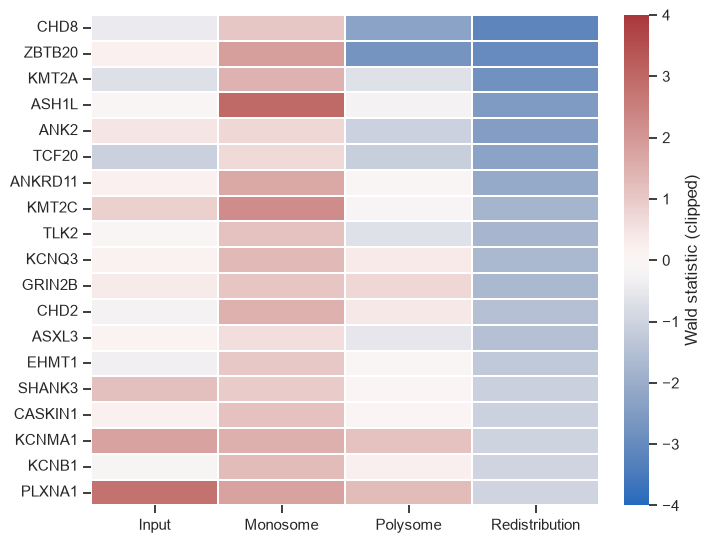

,geneId,geneName,asdAdjustedPValue,fuAsd72,fuAsd185,monosomeLeadingEdge,redistributionLeadingEdge,sharedLeadingEdge,inputLog2FoldChange,inputStatistic,...,polysomeTranscriptGeneFdr,polysomeWithoutParentGeneFdr,polysomeLeadTranscriptId,redistributionLog2FoldChange,redistributionStatistic,redistributionAdjustedPValue,redistributionTranscriptGeneFdr,redistributionWithoutParentGeneFdr,redistributionLeadTranscriptId,dtuConfirmed
98,ENSG00000100888,CHD8,0.000000e+00,True,True,True,True,True,-0.125820,-0.447480,...,False,False,ENST00000553870.2,-1.041299,-3.127598,0.213470,False,False,ENST00000553870.2,False
327,ENSG00000251322,SHANK3,0.000000e+00,True,True,True,True,True,0.305714,1.189746,...,False,False,ENST00000664402.3,-0.302382,-1.064686,0.791477,False,False,ENST00000659388.2,False
51,ENSG00000173575,CHD2,3.608225e-16,True,True,True,True,True,-0.075671,-0.229122,...,False,False,ENST00000627622.2,-0.342454,-1.490385,0.668662,False,False,ENST00000625662.3,False
32,ENSG00000273079,GRIN2B,3.119727e-15,True,True,True,True,True,0.240314,0.313557,...,False,False,NaN,-1.165624,-1.677000,0.610824,False,False,NaN,False
35,ENSG00000116539,ASH1L,1.458531e-11,True,True,True,True,True,-0.037648,-0.101211,...,False,False,ENST00000677992.1,-0.982665,-2.519962,0.361536,False,False,ENST00000677992.1,False
973,ENSG00000141431,ASXL3,9.291739e-11,True,True,True,True,True,0.058342,0.154808,...,False,False,ENST00000696964.1,-0.462789,-1.487472,0.669458,False,False,ENST00000681521.1,False
58,ENSG00000181090,EHMT1,3.721567e-06,True,True,True,True,True,-0.088426,-0.341082,...,False,False,ENST00000494249.5,-0.348399,-1.260371,0.732148,False,False,ENST00001063685.1,False
209,ENSG00000145362,ANK2,8.128724e-06,True,True,True,True,True,0.177724,0.438228,...,False,False,ENST00000510275.8,-0.621399,-2.447492,0.377525,False,False,ENST00000682049.1,False
257,ENSG00000146872,TLK2,1.175003e-05,True,True,True,True,True,-0.004115,-0.021395,...,False,False,ENST00000580203.1,-0.590709,-1.777687,0.588406,False,False,ENST00001014803.1,False
314,ENSG00000055609,KMT2C,1.591306e-05,True,True,True,True,True,0.244085,0.845867,...,False,False,ENST00000684768.1,-0.649738,-1.797033,0.581907,False,False,ENST00000684768.1,False


In [12]:
# Visualize shared Fu risk-gene signals across molecular layers.

shared_candidates = fu_leading_edge_genes.loc[
    fu_leading_edge_genes['sharedLeadingEdge']
].copy()
statistic_columns = [
    f'{analysis}Statistic' for analysis in ANALYSES
]
candidate_statistics = shared_candidates.set_index('geneName')[
    statistic_columns
].copy()
candidate_statistics.columns = [LABELS[analysis] for analysis in ANALYSES]
candidate_statistics = candidate_statistics.sort_values(
    'Redistribution'
).clip(lower = -4, upper = 4)

figure, ax = plt.subplots(
    figsize = (7, max(5, 0.28 * len(candidate_statistics))),
    constrained_layout = True,
)
sns.heatmap(
    candidate_statistics,
    cmap = 'vlag',
    center = 0,
    vmin = -4,
    vmax = 4,
    linewidths = 0.25,
    linecolor = 'white',
    cbar_kws = {'label': 'Wald statistic (clipped)'},
    ax = ax,
)
ax.set(xlabel = '', ylabel = '')
plt.show()

display(fu_leading_edge_genes.loc[fu_leading_edge_genes['sharedLeadingEdge']])


In [13]:
# Save complete tables and an auditable method record.


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


fu_genes.to_csv(
    RESULTS_DIR / 'fuAsdGenes.tsv',
    sep = '\t',
    index = False,
)
transcript_gene_evidence.to_csv(
    RESULTS_DIR / 'transcriptGeneEvidence.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
transcript_gene_sensitivity.to_csv(
    RESULTS_DIR / 'transcriptGeneSensitivity.tsv',
    sep = '\t',
    index = False,
)
transcript_selection_bias.to_csv(
    RESULTS_DIR / 'transcriptGeneSelectionBias.tsv',
    sep = '\t',
    index = False,
)
transcript_functional_ora.to_csv(
    RESULTS_DIR / 'transcriptFunctionalOverrepresentation.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
transcript_functional_covariate_sensitivity.to_csv(
    RESULTS_DIR / 'transcriptFunctionalCovariateSensitivity.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
fu_ranked_enrichment.to_csv(
    RESULTS_DIR / 'fuAsdRankedEnrichment.tsv',
    sep = '\t',
    index = False,
)
fu_rank_regression.to_csv(
    RESULTS_DIR / 'fuAsdRankRegression.tsv',
    sep = '\t',
    index = False,
)
fu_transcript_overlap.to_csv(
    RESULTS_DIR / 'fuAsdTranscriptOverlap.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
fu_leave_one_out.to_csv(
    RESULTS_DIR / 'fuAsdLeaveOneOutEnrichment.tsv',
    sep = '\t',
    index = False,
)
fu_normalization_sensitivity.to_csv(
    RESULTS_DIR / 'fuAsdNormalizationSensitivity.tsv',
    sep = '\t',
    index = False,
)
fu_layer_decomposition.to_csv(
    RESULTS_DIR / 'fuAsdLayerDecomposition.tsv',
    sep = '\t',
    index = False,
)
fu_leading_edge_genes.to_csv(
    RESULTS_DIR / 'fuAsdLeadingEdgeGenes.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)

provenance = {
    'contrast': 'ASD versus Unaffected',
    'fuReference': {
        'citation': (
            'Fu et al., Nature Genetics 54, 1320–1331 (2022)'
        ),
        'doi': '10.1038/s41588-022-01104-0',
        'sourceTable': 'Supplementary Table 11',
        'sourceFile': str(FU_PATH.relative_to(ROOT)),
        'sourceSha256': sha256(FU_PATH),
        'primaryTier': 'ASD72; TADA-ASD FDR ≤ 0.001',
        'sensitivityTier': 'ASD185; TADA-ASD FDR ≤ 0.05',
        'excludedTier': (
            'ASD/DD meta-analysis tiers are not labeled as ASD genes'
        ),
    },
    'transcriptGeneTest': (
        'Minimum transcript P value multiplied by the number of '
        'eligible transcripts per gene, followed by Benjamini–Hochberg '
        'across genes within each layer and eligibility variant.'
    ),
    'primaryTranscriptEligibility': VARIANTS[PRIMARY_VARIANT],
    'parentGeneInterpretation': (
        'Without parent-gene FDR is a descriptive qualifier and does '
        'not prove isoform-specific regulation.'
    ),
    'functionalOra': (
        'One-sided hypergeometric test within the layer-specific '
        'gene-centric transcript universe; Benjamini–Hochberg within '
        'analysis, collection, and direction. Terms passing FDR with '
        'at least three overlaps receive a post-selection logistic '
        'sensitivity analysis adjusted for transcript count and parent '
        'gene abundance; this sensitivity cannot create discoveries.'
    ),
    'fuRankedEnrichment': (
        'GSEA gene-set permutations on signed gene-level Wald '
        'statistics; 1,000 permutations; global BH additionally '
        'reported across all eight nested-tier/layer tests.'
    ),
    'fuRankRegression': (
        'HC3-robust linear regression of rank-normalized signed Wald '
        'statistics on Fu membership, adjusted for log parent-gene '
        'base mean and log annotated transcript count; global BH '
        'reported across eight nested-tier/layer tests.'
    ),
    'layerDependence': (
        'Monosome and redistribution share observations and are not '
        'treated as independent replication.'
    ),
    'methodReferences': {
        'FuASD': 'https://doi.org/10.1038/s41588-022-01104-0',
        'GSEA': 'https://doi.org/10.1073/pnas.0506580102',
        'BenjaminiHochberg': (
            'https://doi.org/10.1111/j.2517-6161.1995.tb02031.x'
        ),
        'SynGO': 'https://doi.org/10.1016/j.neuron.2019.05.002',
    },
    'software': {
        package: version(package)
        for package in (
            'gseapy',
            'numpy',
            'openpyxl',
            'pandas',
            'scipy',
            'statsmodels',
            'matplotlib',
            'seaborn',
        )
    },
}
with (RESULTS_DIR / 'diseaseConvergenceProvenance.json').open(
    'w',
    encoding = 'utf-8',
) as handle:
    json.dump(provenance, handle, indent = 2, ensure_ascii = False)


In [14]:
# Verify the final statistical and biological output contracts.

if transcript_gene_evidence.duplicated(['analysis', 'geneId']).any():
    raise ValueError('Primary transcript-gene evidence is not unique.')
if not fu_ranked_enrichment['pValue'].between(0, 1).all():
    raise ValueError('Fu enrichment P values are invalid.')
if not fu_ranked_enrichment['globalAdjustedPValue'].between(0, 1).all():
    raise ValueError('Fu enrichment adjusted P values are invalid.')
if fu_leave_one_out['omittedParticipantId'].nunique() != 6:
    raise ValueError('Expected six leave-one-donor-out fits.')
if fu_leading_edge_genes['sharedLeadingEdge'].sum() != len(shared_leading):
    raise ValueError('Shared leading-edge count is inconsistent.')

primary_display = fu_ranked_enrichment.loc[
    fu_ranked_enrichment['tier'].eq(primary_tier),
    [
        'context',
        'normalizedEnrichmentScore',
        'pValue',
        'globalAdjustedPValue',
        'leadingEdgeGenesCount',
    ],
].sort_values('context')
print(
    f'Fu ASD72 redistribution direction: '
    f'{primary_ranked.loc["redistribution", "direction"]}'
)
print(
    f'Leave-one-donor-out negative fits: '
    f'{int(primary_loo["negativeFits"])}/'
    f'{int(primary_loo["omittedFits"])}'
)
print(f'Shared monosome/redistribution leading edge: {len(shared_leading)}')
display(primary_display)
display(
    primary_regression.reset_index()[[
        'analysis',
        'coefficient',
        'pValue',
        'adjustedPValue',
        'direction',
    ]].sort_values('analysis')
)


Fu ASD72 redistribution direction: negative
Leave-one-donor-out negative fits: 6/6
Shared monosome/redistribution leading edge: 19


,context,normalizedEnrichmentScore,pValue,globalAdjustedPValue,leadingEdgeGenesCount
0,input,0.825602,0.817330,0.934092,26
2,monosome,1.768953,0.007712,0.015424,33
4,polysome,-1.123450,0.243243,0.389189,24
6,redistribution,-2.313158,0.000999,0.002664,28


,analysis,coefficient,pValue,adjustedPValue,direction
0,input,0.110351,2.442388e-01,2.791300e-01,positive
1,monosome,0.505205,3.161032e-07,7.237806e-07,positive
2,polysome,-0.160145,1.346578e-01,1.795437e-01,negative
3,redistribution,-0.709060,1.738033e-10,6.952131e-10,negative
